# Where could a drive-through coffee shop fit in Cook County?

**Analysis notebook** for the Cook County coffee site-selection project (a hypothetical portfolio study, not a real site recommendation).

The scoring pipeline itself runs in PostGIS (see `sql/`). This notebook repeats the core of it in Python with GeoPandas, using only the files in this repository, so it runs with no database and no API keys. It does five things:

1. Rebuilds the 500 m hexagon grid as polygons and projects it to meters (EPSG:26916).
2. Recomputes each cell's score from its twelve stored factors.
3. Finds the same top 15 sites as the published map, as a check on the Python against the SQL.
4. Stress-tests the ranking by randomly changing the weights, and tries four named scenarios.
5. Compares the simple 1.5 km radius with 5 and 10 minute drive-time areas.

Everything here is derived from public data (Overture Maps, Census ACS, IDOT traffic counts, the competitor chains' public store locators and OpenStreetMap through openrouteservice). Competition counts are lower bounds because Overture is incomplete and the chain list has four chains and no independent shops.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Find the repository root whether this is run from the root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "app" / "data").exists() else Path.cwd().parent
UTM = 26916                      # NAD83 / UTM zone 16N, meters
EDGE_M = 288.675                 # hexagon edge length (500 m across the flat sides)
SPACING_M = 3000                 # distinct sites must be at least this far apart
N_SITES = 15

# One teal ramp for score (light to dark), one orange accent for the chosen sites
RAMP = ["#eef0ee", "#cfe3e1", "#93c6c4", "#4f9ea4", "#1f7480", "#0d4766"]
BREAKS = [35, 45, 55, 63, 70]
ACCENT = "#e8590c"
INK, MUTED = "#222222", "#6b6b6b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#bbbbbb", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "font.size": 10})
print("Repository root:", ROOT.name)

Repository root: repo


## 1. Load the cells and rebuild the hexagons

`app/data/hex_cells.csv` holds one row per hexagon: its center, the twelve scoring factors (each stored as a 0 to 100 percentile), the stored score, and the inputs behind them. The file keeps only the center point, so I rebuild each hexagon as a polygon in meters. A sound rebuild gives every cell the same area, 0.2165 km² for a 500 m hexagon.

In [2]:
cells = pd.read_csv(ROOT / "app" / "data" / "hex_cells.csv")
published = pd.read_csv(ROOT / "app" / "data" / "sites.csv")      # the map's top 66 sites

pts = gpd.GeoDataFrame(cells, geometry=gpd.points_from_xy(cells.lon, cells.lat), crs=4326).to_crs(UTM)

angles = np.radians(np.arange(6) * 60)
offsets = np.column_stack([EDGE_M * np.cos(angles), EDGE_M * np.sin(angles)])
from shapely.geometry import Polygon
hexes = pts.copy()
hexes["geometry"] = [Polygon(offsets + (p.x, p.y)) for p in pts.geometry]

print(f"{len(hexes):,} hexagons, CRS EPSG:{hexes.crs.to_epsg()}")
print(f"Area per hexagon: {hexes.area.min()/1e6:.4f} to {hexes.area.max()/1e6:.4f} km2 (expected 0.2165)")
print(f"Covers {hexes.area.sum()/1e6:,.0f} km2")

11,584 hexagons, CRS EPSG:26916
Area per hexagon: 0.2165 to 0.2165 km2 (expected 0.2165)
Covers 2,508 km2


## 2. Recompute the score

The score is a weighted average of twelve factors. The default weights are the ones on the published map, grouped as competition (30), people and income (26), driving habits (13), road traffic (15) and nearby businesses (16). `s_nov` is already flipped, so a high value means few households without a vehicle.

The stored factors are whole numbers, so a recomputed score can differ from the stored one by a few tenths. The notebook checks how large that difference gets.

In [3]:
WEIGHTS = {"s_comp": .18, "s_rpc": .12, "s_pop": .13, "s_inc": .13, "s_da": .08, "s_nov": .05,
           "s_traf": .12, "s_busy": .03, "s_gas": .05, "s_ff": .05, "s_off": .03, "s_groc": .03}
FACTORS = list(WEIGHTS)
w0 = np.array(list(WEIGHTS.values()))
X = hexes[FACTORS].fillna(0).to_numpy(float)       # missing factor values count as 0

def score(weights, X=X):
    return np.round(X @ (weights / weights.sum()), 1)

hexes["score_py"] = score(w0)
diff = (hexes.score_py - hexes.score).abs()
print(f"Weights sum to {w0.sum():.2f}")
print(f"Recomputed vs stored score: max difference {diff.max():.1f}, mean {diff.mean():.2f}, correlation {hexes.score_py.corr(hexes.score):.4f}")

Weights sum to 1.00
Recomputed vs stored score: max difference 0.4, mean 0.07, correlation 0.9999


## 3. Candidate cells and distinct local peaks

A cell is a candidate only if it has at least 5,000 residents within 1.5 km and no more than 15% of households without a vehicle. A **site** is a candidate cell that no other candidate within 3 km beats, so the top 15 are 15 separate places and not one busy corridor repeated. When two cells tie, the more southern one wins (the same rule as the database).

GeoPandas does the neighbor search: buffer every candidate by 3 km and spatially join it to the candidate points.

In [4]:
hexes["eligible"] = hexes.eligible.astype(str).str.lower().eq("true")
cand = hexes[hexes.eligible].reset_index()          # keeps the original row number in column 'index'
print(f"{len(cand):,} candidate cells out of {len(hexes):,}")

# Candidate neighbors within 3 km: a buffer join finds them, an exact distance check trims the polygon edge
buf = cand[["geometry"]].copy()
buf["geometry"] = cand.geometry.centroid.buffer(SPACING_M + 10)
cent = cand[["geometry"]].copy()
cent["geometry"] = cand.geometry.centroid
pairs = gpd.sjoin(buf, cent, predicate="intersects").reset_index()
pairs = pairs.rename(columns={"index": "a", "index_right": "b"})
pairs = pairs[pairs.a != pairs.b]
xy = np.column_stack([cent.geometry.x, cent.geometry.y])
dist = np.hypot(*(xy[pairs.a] - xy[pairs.b]).T)
pairs = pairs[dist <= SPACING_M]
a, b = pairs.a.to_numpy(), pairs.b.to_numpy()
south_wins = cand.lat.rank(method="first").to_numpy()      # tie-break key: lower = more southern

def find_peaks(s):
    """Candidate cells (positions in `cand`) that no neighbor within 3 km beats, best first."""
    beaten = np.zeros(len(s), bool)
    sa, sb = s[a], s[b]
    beaten[a[(sb > sa) | ((sb == sa) & (south_wins[b] < south_wins[a]))]] = True
    p = np.flatnonzero(~beaten)
    return p[np.lexsort((south_wins[p], -s[p]))]

peaks = find_peaks(cand.score.to_numpy())               # stored score = the published ranking
print(f"{len(pairs)//2:,} neighbor pairs, {len(peaks)} distinct local peaks")

7,165 candidate cells out of 11,584


359,549 neighbor pairs, 66 distinct local peaks


**Check against the published sites.** Each of the top 15 found here should sit on top of a site in `sites.csv`. Matching is by distance: a match closer than 1 m is the same cell.

In [5]:
pub = gpd.GeoDataFrame(published, geometry=gpd.points_from_xy(published.lon, published.lat), crs=4326).to_crs(UTM)
pub_xy = np.column_stack([pub.geometry.x, pub.geometry.y])

def match_to_published(positions):
    d, j = cKDTree(pub_xy).query(xy[positions])
    return d, j + 1                                        # published site_rank

d, rank = match_to_published(peaks[:N_SITES])
print("Top 15 found here match published ranks:", [int(x) for x in rank])
print(f"Largest distance to a published site: {d.max():.1f} m")

d_all, rank_all = match_to_published(peaks)
print(f"All {len(peaks)} peaks: {len(set(rank_all))} distinct published sites matched, max distance {d_all.max():.1f} m")

# With the score recomputed from the rounded factors instead of the stored one
peaks_py = find_peaks(cand.score_py.to_numpy())
d2, rank2 = match_to_published(peaks_py[:N_SITES])
print("Recomputed score, top 15 ranks:", [int(x) for x in rank2], "| same 15 sites:", set(rank2) == set(range(1, N_SITES + 1)))

Top 15 found here match published ranks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Largest distance to a published site: 0.6 m
All 66 peaks: 66 distinct published sites matched, max distance 0.7 m
Recomputed score, top 15 ranks: [1, 2, 3, 4, 6, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15] | same 15 sites: True


## 4. Map of the scores and the top 15

Same ramp as the web map. Hexagons that are not candidates (too few residents or too many households without a vehicle) are faded. The orange circles are the top 15 sites.

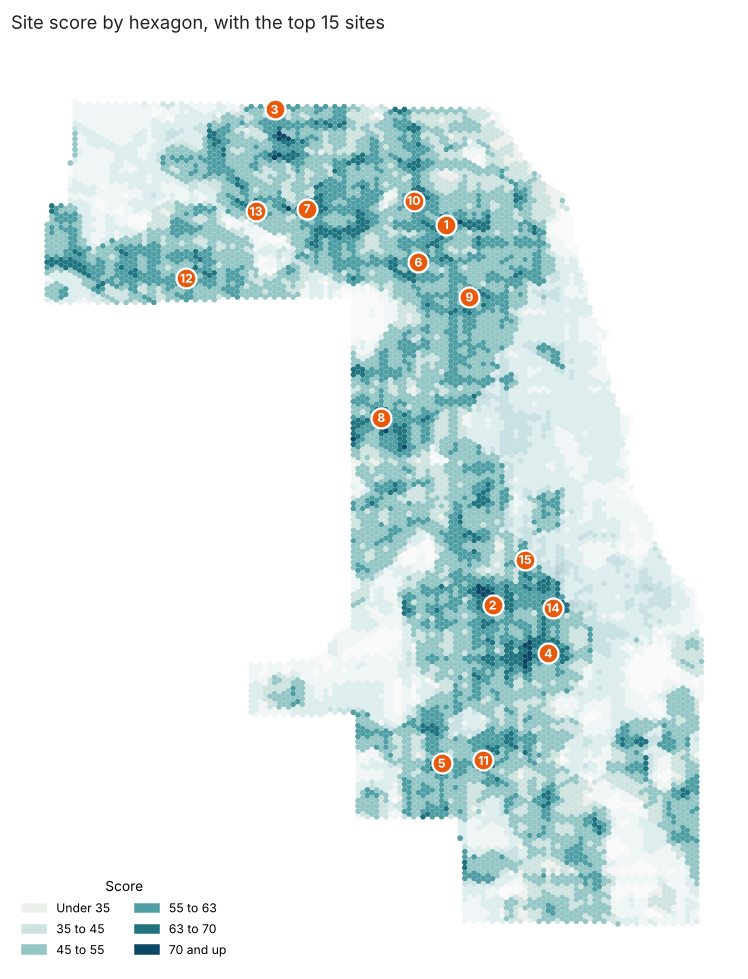

In [6]:
cmap = ListedColormap(RAMP)
norm = BoundaryNorm([0] + BREAKS + [100], cmap.N)

fig, ax = plt.subplots(figsize=(7.5, 9))
hexes[~hexes.eligible].plot(ax=ax, column="score", cmap=cmap, norm=norm, alpha=0.30, linewidth=0)
hexes[hexes.eligible].plot(ax=ax, column="score", cmap=cmap, norm=norm, linewidth=0)
top = cand.iloc[peaks[:N_SITES]]
ax.scatter(top.geometry.centroid.x, top.geometry.centroid.y, s=170, color=ACCENT, edgecolor="white", linewidth=1.5, zorder=3)
for n, p in enumerate(top.geometry.centroid, start=1):
    ax.annotate(str(n), (p.x, p.y), ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=4)
ax.set_axis_off()
ax.set_title("Site score by hexagon, with the top 15 sites", loc="left", color=INK, fontsize=12)
labels = ["Under 35", "35 to 45", "45 to 55", "55 to 63", "63 to 70", "70 and up"]
for i, (c, lab) in enumerate(zip(RAMP, labels)):
    ax.add_patch(plt.Rectangle((0, 0), 0, 0, color=c, label=lab))
ax.legend(title="Score", loc="lower left", frameon=False, fontsize=8, title_fontsize=9, ncols=2)
plt.tight_layout()
plt.show()

## 5. Stress test: how stable is each site?

The weights are a judgment call, so I test how much the answer depends on them. Each run multiplies every factor weight by a random number between 0.5 and 1.5, recomputes the score, finds the top 15 and records which sites made it. Over 300 runs, a site that appears in 90% or more depends little on the exact weights. A site under 60% only wins for some mixes of priorities. A fixed random seed makes the result repeatable. The SQL version of this test used other random draws and the unrounded factors, so a site near a threshold can differ by a few points, and the count at the 90% line can differ by a site or two.

In [7]:
rng = np.random.default_rng(42)
Xc = X[cand["index"].to_numpy()]                       # factors for candidate cells only
hits = np.zeros(len(cand))
N_RUNS = 300
for _ in range(N_RUNS):
    w = w0 * rng.uniform(0.5, 1.5, w0.size)
    hits[find_peaks(score(w, Xc))[:N_SITES]] += 1
pct = hits / N_RUNS * 100

# Look up the stress-test share for each of the 66 published sites
site_pos = peaks                                       # candidate positions of the 66 sites, best first
stab = pd.DataFrame({"site_rank": rank_all, "stability_here": pct[site_pos]}).sort_values("site_rank").set_index("site_rank")
stab = stab.join(published.set_index("site_rank")[["pct_in_top15", "nearest_roads"]])
print(f"Correlation with the SQL stress test (also 300 runs): {stab.stability_here.corr(stab.pct_in_top15):.3f}")
print(f"Largest gap: {(stab.stability_here - stab.pct_in_top15).abs().max():.0f} percentage points (different random draws)")
print(f"Sites in the top 15 in 90%+ of runs: {(stab.stability_here.loc[1:15] >= 90).sum()} of 15 | under 60%: {(stab.stability_here.loc[1:15] < 60).sum()} of 15")

Correlation with the SQL stress test (also 300 runs): 0.998
Largest gap: 9 percentage points (different random draws)
Sites in the top 15 in 90%+ of runs: 4 of 15 | under 60%: 4 of 15


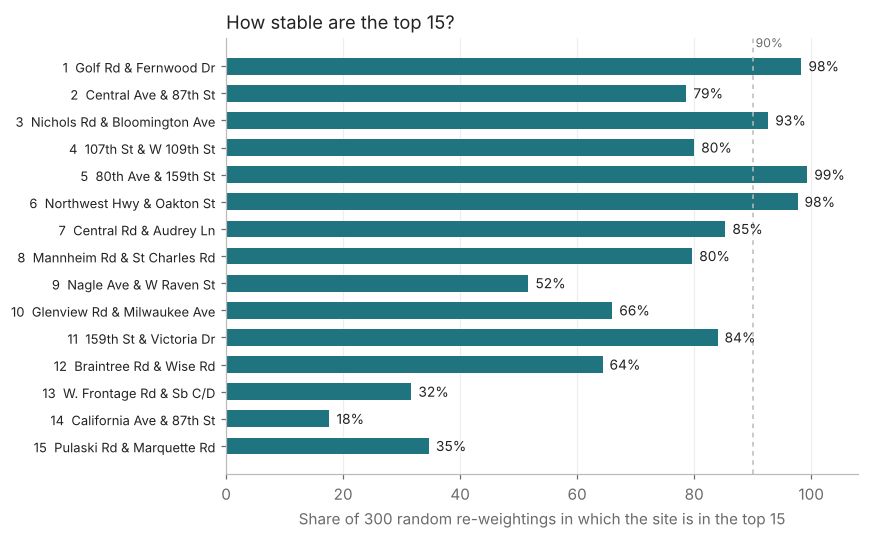

In [8]:
s = stab.loc[1:N_SITES]
fig, ax = plt.subplots(figsize=(8, 5))
ypos = np.arange(len(s))[::-1]
ax.barh(ypos, s.stability_here, color=RAMP[4], height=0.62)
for y, v in zip(ypos, s.stability_here):
    ax.text(v + 1.2, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r}  {n}" for r, n in zip(s.index, s.nearest_roads)], fontsize=8.5, color=INK)
ax.axvline(90, color="#bbbbbb", linewidth=1, linestyle=(0, (3, 3)))
ax.text(90.5, ypos[0] + 0.7, "90%", fontsize=8, color=MUTED)
ax.set_xlim(0, 108)
ax.set_xlabel("Share of 300 random re-weightings in which the site is in the top 15")
ax.set_title("How stable are the top 15?", loc="left", color=INK, fontsize=12)
ax.grid(axis="x", color="#eeeeee"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 6. Four scenarios

Four questions about what drives the result: what if competition did not count at all, if only demand counted, if road traffic were ignored, or if competition counted double. For each, the table shows how many of the 15 published sites would still be in the top 15. (The SQL run of the same scenarios gave 4 instead of 5 for the no-traffic case, from the rounding of stored factors.)

In [9]:
GROUPS = {"competition": ["s_comp", "s_rpc"], "people": ["s_pop", "s_inc"], "driving": ["s_da", "s_nov"],
          "traffic": ["s_traf", "s_busy"], "nearby": ["s_gas", "s_ff", "s_off", "s_groc"]}
def scenario_weights(mult):
    return np.array([WEIGHTS[f] * next(mult.get(g, 1) for g, fs in GROUPS.items() if f in fs) for f in FACTORS])

SCENARIOS = {"No competition terms": {"competition": 0},
             "Demand only (people x2, no competition)": {"competition": 0, "people": 2},
             "No road traffic terms": {"traffic": 0},
             "Competition doubled": {"competition": 2}}
base15 = set(peaks[:N_SITES])
rows = []
for name, mult in SCENARIOS.items():
    new = find_peaks(score(scenario_weights(mult), Xc))[:N_SITES]
    rows.append({"scenario": name, "of the 15 still in the top 15": len(base15 & set(new))})
scen = pd.DataFrame(rows).set_index("scenario")
scen

,of the 15 still in the top 15
scenario,
No competition terms,0
"Demand only (people x2, no competition)",0
No road traffic terms,5
Competition doubled,10


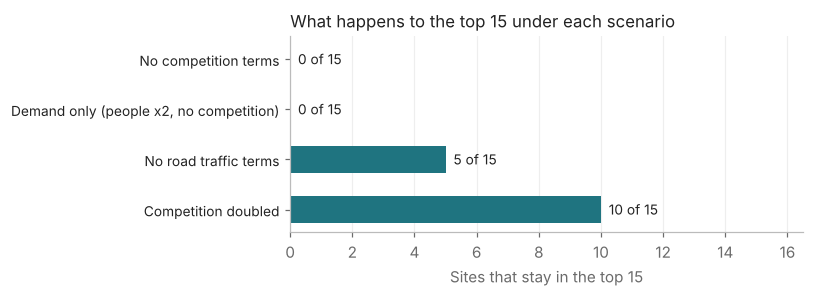

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
y = np.arange(len(scen))[::-1]
vals = scen.iloc[:, 0].to_numpy()
ax.barh(y, vals, color=RAMP[4], height=0.55)
for yy, v in zip(y, vals):
    ax.text(v + 0.25, yy, f"{v} of 15", va="center", fontsize=9, color=INK)
ax.set_yticks(y); ax.set_yticklabels(scen.index, color=INK, fontsize=9)
ax.set_xlim(0, 16.5); ax.set_xlabel("Sites that stay in the top 15")
ax.set_title("What happens to the top 15 under each scenario", loc="left", color=INK, fontsize=11)
ax.grid(axis="x", color="#eeeeee"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 7. Radius or drive time?

The score counts residents and competitors within 1.5 km, a straight-line circle. A customer drives, so `web/isochrones.geojson` holds 5 and 10 minute drive-time areas (openrouteservice, OpenStreetMap data, free-flow speeds, CC BY-SA 4.0) for each of the 66 sites. This section asks how much the two ways of counting agree.

In [11]:
iso = gpd.read_file(ROOT / "web" / "isochrones.geojson")
i5 = iso[iso.minutes == 5].set_index("site_rank")
i10 = iso[iso.minutes == 10].set_index("site_rank")
cmp_ = pd.DataFrame({"pop_radius": i10.pop_radius, "pop_5min": i5["pop"], "pop_10min": i10["pop"], "low_conf": i5.low_conf})
cmp_["ratio_10min"] = cmp_.pop_10min / cmp_.pop_radius

rho5, rho10 = spearmanr(cmp_.pop_radius, cmp_.pop_5min)[0], spearmanr(cmp_.pop_radius, cmp_.pop_10min)[0]
print(f"{len(cmp_)} sites. Rank correlation of residents within 1.5 km with the 5 minute area: {rho5:.2f}, with the 10 minute area: {rho10:.2f}")
print(f"A 10 minute drive area holds on average {cmp_.ratio_10min.mean():.1f} times the residents of the 1.5 km radius (range {cmp_.ratio_10min.min():.1f} to {cmp_.ratio_10min.max():.1f})")
print("Sites flagged low confidence (unusually small 5 minute area):", sorted(cmp_.index[cmp_.low_conf]))

66 sites. Rank correlation of residents within 1.5 km with the 5 minute area: 0.78, with the 10 minute area: 0.80
A 10 minute drive area holds on average 8.5 times the residents of the 1.5 km radius (range 2.8 to 26.6)
Sites flagged low confidence (unusually small 5 minute area): [13, 20, 40]


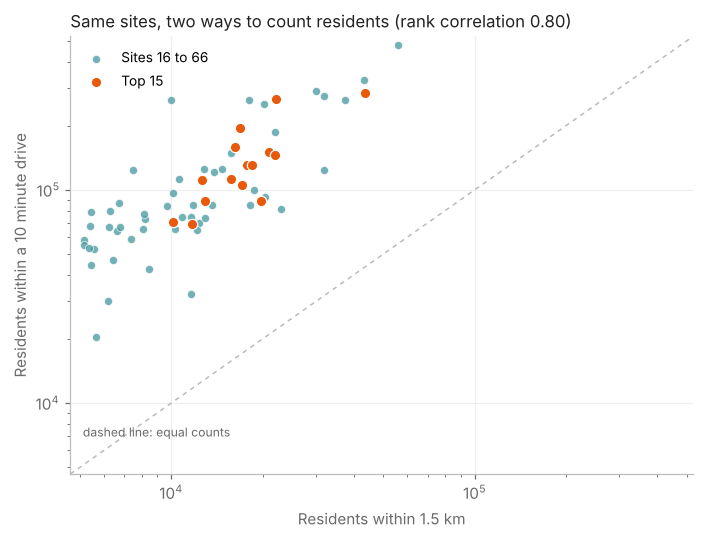

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
rest = cmp_[cmp_.index > N_SITES]; top15 = cmp_[cmp_.index <= N_SITES]
ax.scatter(rest.pop_radius, rest.pop_10min, s=28, color=RAMP[3], alpha=0.8, label="Sites 16 to 66", edgecolor="white", linewidth=0.5)
ax.scatter(top15.pop_radius, top15.pop_10min, s=46, color=ACCENT, label="Top 15", edgecolor="white", linewidth=0.8)
lim = [cmp_.pop_radius.min() * 0.9, cmp_.pop_10min.max() * 1.1]
ax.plot(lim, lim, color="#bbbbbb", linewidth=1, linestyle=(0, (3, 3)))
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Residents within 1.5 km"); ax.set_ylabel("Residents within a 10 minute drive")
ax.set_title(f"Same sites, two ways to count residents (rank correlation {rho10:.2f})", loc="left", color=INK, fontsize=11)
ax.text(lim[0] * 1.1, lim[0] * 1.5, "dashed line: equal counts", fontsize=8, color=MUTED)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.grid(color="#eeeeee"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 8. A reality check against the chain list

The competition factor mixes Overture places with a public list of Starbucks, Dunkin', Dutch Bros and 7 Brew stores (`data/chain_locations_public.csv`: brand, latitude and longitude, collected from each brand's store locator in June 2026). As an independent look, count how many listed chain stores sit within 1.5 km of each top-15 site.

In [13]:
chains = pd.read_csv(ROOT / "data" / "chain_locations_public.csv")
chain_pts = gpd.GeoDataFrame(chains, geometry=gpd.points_from_xy(chains.lon, chains.lat), crs=4326).to_crs(UTM)

site_circles = top[["geometry"]].copy()
site_circles["geometry"] = top.geometry.centroid.buffer(1500)
site_circles["site"] = range(1, N_SITES + 1)
near = gpd.sjoin(chain_pts, site_circles, predicate="within")
count = near.groupby("site").size().reindex(range(1, N_SITES + 1), fill_value=0)

# For comparison: the same count around every candidate cell
all_circles = cand[["geometry"]].copy()
all_circles["geometry"] = cand.geometry.centroid.buffer(1500)
all_counts = gpd.sjoin(chain_pts, all_circles, predicate="within").groupby("index_right").size().reindex(range(len(cand)), fill_value=0)

print(f"Listed chain stores within 1.5 km of a top-15 site: {count.sum()} in total; {(count == 0).sum()} of 15 sites have none")
print(f"Average for all {len(cand):,} candidate cells: {all_counts.mean():.1f} stores within 1.5 km")
print("Per site:", {int(k): int(v) for k, v in count.items()})

Listed chain stores within 1.5 km of a top-15 site: 3 in total; 12 of 15 sites have none
Average for all 7,165 candidate cells: 1.0 stores within 1.5 km
Per site: {1: 1, 2: 0, 3: 0, 4: 1, 5: 0, 6: 0, 7: 0, 8: 0, 9: 1, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0}


## What this shows

- **The Python reproduces the database.** The same 15 sites come out of the GeoPandas score as out of the PostGIS score. Among the top 15, recomputing from the rounded factors only swaps the order of sites 5 and 6.
- **Some sites are robust and some are not.** A handful of the top 15 stay in the top 15 in nearly every random re-weighting, and several only win under particular priorities. The map should not be read as 15 equally good answers.
- **Competition and demand do the work.** Dropping the competition terms, or counting demand alone, replaces all 15 sites; ignoring road traffic changes about two thirds of them. Doubling the weight on competition keeps most.
- **The 1.5 km radius is a rough stand-in for a drive.** The two ways of counting mostly agree on which sites are large (rank correlation 0.80), but a 10 minute drive reaches about 8.5 times as many residents on average, so a drive-through study should lean on the drive-time areas.
- **The chain list agrees with the picture.** Most top-15 sites have no listed chain store within 1.5 km, as expected for places picked for low competition.

## Limits

- **Competition is a lower bound.** Overture is incomplete, the chain list covers four chains, and independent coffee shops are not in it.
- **A traffic count is not an audience.** Traffic counts (AADT) come from Illinois only.
- **Drive-time areas use free-flow speeds**, so rush-hour areas are smaller.
- **Whole-number factors** make a recomputed score differ from the stored one by a few tenths.
- **No site-level reality.** Parcels, zoning, lot access, rent and permitting are not in the data. The top sites are places worth a visit, not places to build.